In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.ensemble import IsolationForest


In [5]:
df = pd.read_csv('adult_with_headers (1).csv')
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [6]:
df.shape

(32561, 15)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [8]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,32561.0,NaN,NaN,NaN,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
workclass,32561,9,Private,22696,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,32561.0,NaN,NaN,NaN,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education,32561,16,HS-grad,10501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_num,32561.0,NaN,NaN,NaN,10.080679,2.57272,1.0,9.0,10.0,12.0,16.0
marital_status,32561,7,Married-civ-spouse,14976,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,32561,15,Prof-specialty,4140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,32561,6,Husband,13193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,32561,5,White,27816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,32561,2,Male,21790,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
dtype: int64

In [10]:
df.duplicated().sum()

24

In [11]:
df = df.drop_duplicates().copy()
print('Shape after removing duplicates:', df.shape)

Shape after removing duplicates: (32537, 15)


In [12]:
# remove any extra spaces in text columns
cat_cols = df.select_dtypes(include='object').columns
for col in cat_cols:
    df[col] = df[col].str.strip()

# fill missing categorical values
for col in cat_cols:
    df[col] = df[col].fillna('Unknown')

print('Total missing values:', df.isnull().sum().sum())

Total missing values: 0


In [13]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
dtype: int64

In [14]:
df['income'].value_counts()

income
<=50K    24698
>50K      7839
Name: count, dtype: int64

In [15]:
df.select_dtypes(include='object').nunique().sort_values()

sex                2
income             2
race               5
relationship       6
marital_status     7
workclass          9
occupation        15
education         16
native_country    42
dtype: int64

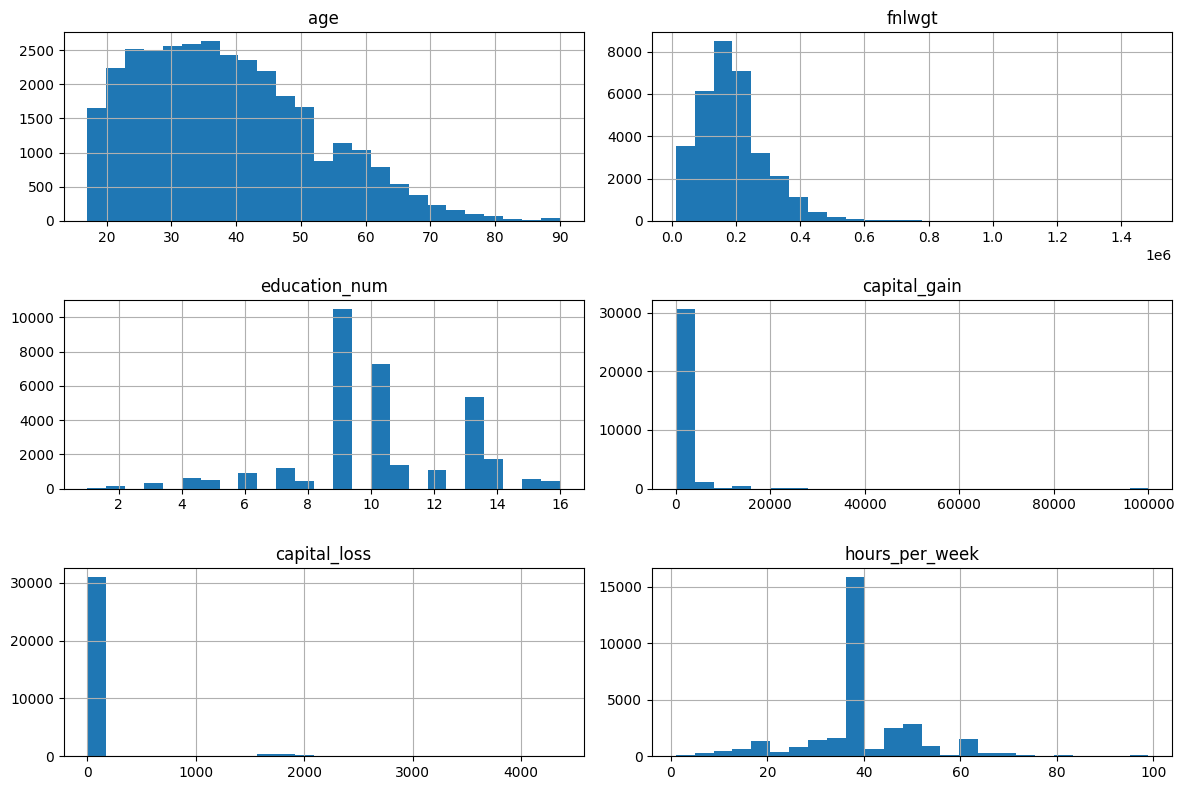

In [16]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
df[num_cols].hist(figsize=(12, 8), bins=25)
plt.tight_layout()
plt.show()

In [17]:
df['capital_net'] = df['capital_gain'] - df['capital_loss']
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 25, 40, 60, 100],
    labels=['25 and below', '26-40', '41-60', 'Above 60']
)

df[['age', 'age_group', 'capital_gain', 'capital_loss', 'capital_net']].head()

,age,age_group,capital_gain,capital_loss,capital_net
0,39,26-40,2174,0,2174
1,50,41-60,0,0,0
2,38,26-40,0,0,0
3,53,41-60,0,0,0
4,28,26-40,0,0,0


Skew before transformation: 11.949402833551463


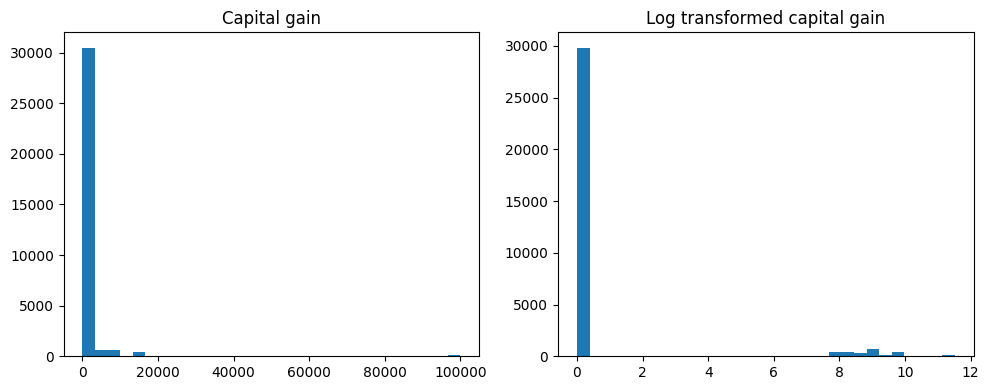

Skew after transformation: 3.094666793136126


In [18]:
print('Skew before transformation:', df['capital_gain'].skew())

df['capital_gain_log'] = np.log1p(df['capital_gain'])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(df['capital_gain'], bins=30)
ax[0].set_title('Capital gain')
ax[1].hist(df['capital_gain_log'], bins=30)
ax[1].set_title('Log transformed capital gain')
plt.tight_layout()
plt.show()

print('Skew after transformation:', df['capital_gain_log'].skew())

## Scaling numerical features

Standard Scaling changes values to have a mean close to 0 and a standard deviation close to 1. It is useful when a method is sensitive to feature scale, such as logistic regression or SVM. Min-Max Scaling moves values into a fixed range, usually 0 to 1; it is useful when a bounded range is wanted. Min-Max scaling can be more affected by outliers, while Standard Scaling does not force values into a fixed range.

These cells demonstrate the two methods on the numerical columns. In a predictive model, fit the scaler on the training data only and use the same fitted scaler on test data.

In [19]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

standard_scaled = df.copy()
standard_scaler = StandardScaler()
standard_scaled[numeric_cols] = standard_scaler.fit_transform(df[numeric_cols])

standard_scaled[numeric_cols].head()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,capital_net,capital_gain_log
0,0.030390,-1.063569,1.134777,0.148292,-0.216743,-0.035664,0.159605,2.830199
1,0.836973,-1.008668,1.134777,-0.145975,-0.216743,-2.222483,-0.133720,-0.299391
2,-0.042936,0.245040,-0.420679,-0.145975,-0.216743,-0.035664,-0.133720,-0.299391
3,1.056950,0.425752,-1.198407,-0.145975,-0.216743,-0.035664,-0.133720,-0.299391
4,-0.776193,1.408066,1.134777,-0.145975,-0.216743,-0.035664,-0.133720,-0.299391


In [20]:
minmax_scaled = df.copy()
minmax_scaler = MinMaxScaler()
minmax_scaled[numeric_cols] = minmax_scaler.fit_transform(df[numeric_cols])

minmax_scaled[numeric_cols].head()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,capital_net,capital_gain_log
0,0.301370,0.044302,0.800000,0.02174,0.0,0.397959,0.062575,0.667492
1,0.452055,0.048238,0.800000,0.00000,0.0,0.122449,0.041742,0.000000
2,0.287671,0.138113,0.533333,0.00000,0.0,0.397959,0.041742,0.000000
3,0.493151,0.151068,0.400000,0.00000,0.0,0.397959,0.041742,0.000000
4,0.150685,0.221488,0.800000,0.00000,0.0,0.397959,0.041742,0.000000


## Encoding categorical columns

One-Hot Encoding makes a separate 0/1 column for each category. It works well for columns with a small number of categories, but it can add many columns. Label Encoding replaces categories with numbers, so it keeps the number of columns smaller. However, the numbers can look ordered even when the categories are not.

I will use One-Hot Encoding for feature columns with fewer than 5 categories. Columns with more than 5 categories will use Label Encoding. The `race` column has exactly 5 categories, so I will Label Encode it to handle the threshold case. The target `income` is encoded separately.

In [21]:
# Find the categorical feature columns (not the target)
categorical_features = [col for col in df.select_dtypes(include=['object', 'category']).columns if col != 'income']

low_cardinality = [col for col in categorical_features if df[col].nunique() < 5]
high_cardinality = [col for col in categorical_features if df[col].nunique() > 5]
exactly_five = [col for col in categorical_features if df[col].nunique() == 5]

print('One-Hot Encoding:', low_cardinality)
print('Label Encoding (>5 categories):', high_cardinality)
print('Label Encoding (exactly 5 categories):', exactly_five)

One-Hot Encoding: ['sex', 'age_group']
Label Encoding (>5 categories): ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'native_country']
Label Encoding (exactly 5 categories): ['race']


In [22]:
encoded_df = df.copy()

# One-Hot Encoding for columns with fewer than 5 categories
encoded_df = pd.get_dummies(encoded_df, columns=low_cardinality)

# Label Encoding for columns with more than 5 categories and the 5-category column
label_encoders = {}
for col in high_cardinality + exactly_five:
    le = LabelEncoder()
    encoded_df[col] = le.fit_transform(encoded_df[col].astype(str))
    label_encoders[col] = le

# Encode the target separately
income_encoder = LabelEncoder()
encoded_df['income'] = income_encoder.fit_transform(encoded_df['income'].astype(str))

encoded_df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,capital_gain,...,native_country,income,capital_net,capital_gain_log,sex_Female,sex_Male,age_group_25 and below,age_group_26-40,age_group_41-60,age_group_Above 60
0,39,7,77516,9,13,4,1,1,4,2174,...,39,0,2174,7.684784,False,True,False,True,False,False
1,50,6,83311,9,13,2,4,0,4,0,...,39,0,0,0.000000,False,True,False,False,True,False
2,38,4,215646,11,9,0,6,1,4,0,...,39,0,0,0.000000,False,True,False,True,False,False
3,53,4,234721,1,7,2,6,0,2,0,...,39,0,0,0.000000,False,True,False,False,True,False
4,28,4,338409,9,13,2,10,5,2,0,...,5,0,0,0.000000,True,False,False,True,False,False


In [23]:
print('Encoded data shape:', encoded_df.shape)
print('Categorical columns left:', encoded_df.select_dtypes(include=['object', 'category']).columns.tolist())

Encoded data shape: (32537, 22)
Categorical columns left: []


## Isolation Forest

Isolation Forest can help flag unusual rows. Here I will identify possible outliers in the numerical columns, but I will not remove them automatically because an unusual value may still be valid.

In [24]:
iso_cols = df.select_dtypes(include=np.number).columns.tolist()
isolation_forest = IsolationForest(contamination=0.02, random_state=42)
df['outlier_flag'] = isolation_forest.fit_predict(df[iso_cols])

print('Rows flagged as possible outliers:', (df['outlier_flag'] == -1).sum())
print('Rows flagged as normal:', (df['outlier_flag'] == 1).sum())
df[['outlier_flag']].value_counts()

Rows flagged as possible outliers: 651
Rows flagged as normal: 31886


outlier_flag
 1              31886
-1                651
Name: count, dtype: int64

## PPS (Predictive Power Score)

PPS measures how well one column can predict another and can find relationships that correlation may not show. If the `ppscore` package is not installed, install it with `%pip install ppscore` in a separate cell and then run the cell below.

In [25]:
try:
    import ppscore as pps

    # Use a sample to keep the calculation quicker
    pps_sample = df.sample(n=min(5000, len(df)), random_state=42).drop(columns=['outlier_flag'])
    pps_results = pps.matrix(pps_sample)
    pps_results = pps_results.sort_values('ppscore', ascending=False)
    display(pps_results.head(20))
except ImportError:
    print('PPS package is not installed. Run %pip install ppscore in a separate cell, then rerun this cell.')

PPS package is not installed. Run %pip install ppscore in a separate cell, then rerun this cell.


## Save the processed dataset

In [26]:
# Save the encoded data for later use
encoded_df.to_csv('adult_preprocessed.csv', index=False)
print('Saved adult_preprocessed.csv')

Saved adult_preprocessed.csv
